In [19]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import make_pipeline 
from sklearn.svm import LinearSVC, SVC 
from scipy.stats import loguniform, uniform


In [7]:
# import dataset 
wine = load_wine(as_frame=True)
print(wine.DESCR)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

In [8]:
# split the data 
X_train, X_test, y_train, y_test = train_test_split(wine.data, wine.target, random_state=42)

In [11]:
# Linear SVM
lin_clf = make_pipeline(StandardScaler(), LinearSVC(dual=True, random_state=42))
# accuracy
cross_val_score(lin_clf, X_train, y_train).mean()

np.float64(0.9774928774928775)

In [12]:
# kernalized SVM
svm_clf = make_pipeline(StandardScaler(), SVC(random_state=42))
# accuracy 
cross_val_score(svm_clf, X_train, y_train).mean()

np.float64(0.9698005698005698)

In [17]:
# setting hyperparameters 
param_distrib = {
    "svc__gamma": loguniform(0.001, 0.1),
    "svc__C": uniform(1, 10)
}
rnd_search_cv = RandomizedSearchCV(svm_clf, param_distrib, n_iter=100, cv=5,
                                   random_state=42)
rnd_search_cv.fit(X_train, y_train)
rnd_search_cv.best_estimator_

rnd_search_cv.best_score_

np.float64(0.9925925925925926)

In [18]:
# accuracy on test set
rnd_search_cv.score(X_test, y_test)

0.9777777777777777

## Results

### Confusion matrix (test set)
Which wines the tuned SVM got right (diagonal) and which it confused with another class.

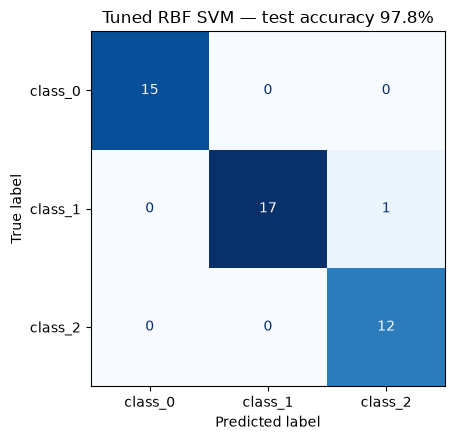

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = rnd_search_cv.best_estimator_
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=wine.target_names, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title(f"Tuned RBF SVM — test accuracy {best_model.score(X_test, y_test):.1%}")
plt.tight_layout()
plt.show()

### Hyperparameter search
Each dot is one (C, gamma) pair tried by `RandomizedSearchCV`; darker means higher cross-validation accuracy. The star is the best pair.

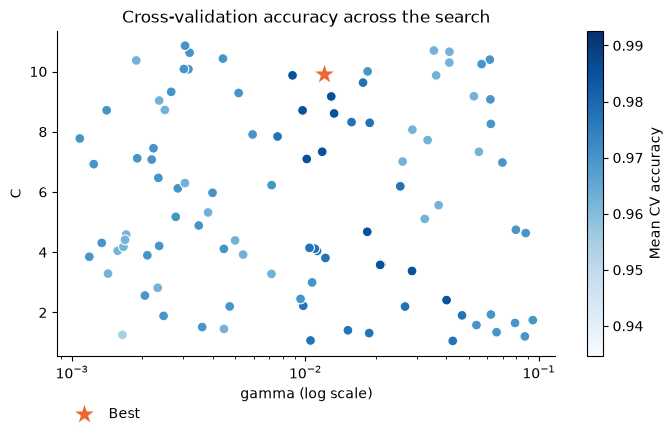

In [21]:
results = pd.DataFrame(rnd_search_cv.cv_results_)
best = rnd_search_cv.best_params_

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(results["param_svc__gamma"].astype(float), results["param_svc__C"].astype(float),
                c=results["mean_test_score"], cmap="Blues", s=50,
                vmin=results["mean_test_score"].min() - 0.02,  # keep the lowest scores visible
                edgecolors="white", linewidths=0.8)
ax.scatter(best["svc__gamma"], best["svc__C"], marker="*", s=300,
           color="#eb6834", edgecolors="white", linewidths=1, label="Best", zorder=3)
ax.set_xscale("log")
ax.set_xlabel("gamma (log scale)")
ax.set_ylabel("C")
ax.set_title("Cross-validation accuracy across the search")
fig.colorbar(sc, ax=ax, label="Mean CV accuracy")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Model comparison
Cross-validation accuracy on the training set for each model, plus the tuned model's score on the held-out test set.

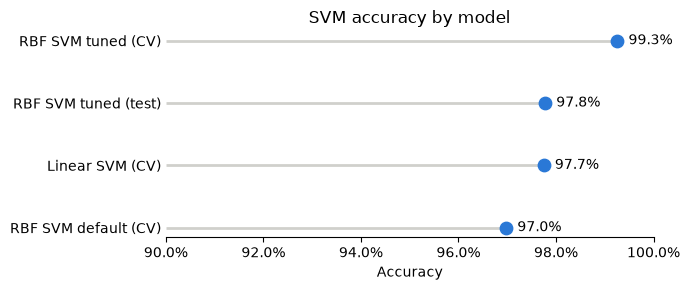

In [22]:
scores = pd.Series({
    "Linear SVM (CV)": cross_val_score(lin_clf, X_train, y_train).mean(),
    "RBF SVM default (CV)": cross_val_score(svm_clf, X_train, y_train).mean(),
    "RBF SVM tuned (CV)": rnd_search_cv.best_score_,
    "RBF SVM tuned (test)": rnd_search_cv.score(X_test, y_test),
})

scores = scores.sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
ax.hlines(scores.index, 0.9, scores.values, color="#d0d0cc", linewidth=2)
ax.scatter(scores.values, scores.index, color="#2a78d6", s=80, zorder=3)
for name, s in scores.items():
    ax.annotate(f"{s:.1%}", (s, name), xytext=(8, 0), textcoords="offset points", va="center")
ax.set_xlim(0.9, 1.0)  # zoomed in: all scores are between 90% and 100%
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Accuracy")
ax.set_title("SVM accuracy by model")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()